# Modul 2

## Import Data

In [ ]:
import pandas as pd

df = pd.read_csv("midterm_hotel_data.csv")

## Describe Data

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 37 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Unnamed: 0                      119390 non-null  int64  
 1   hotel                           119390 non-null  object 
 2   is_canceled                     119390 non-null  int64  
 3   lead_time                       83573 non-null   float64
 4   arrival_date_year               119390 non-null  int64  
 5   arrival_date_month              119390 non-null  object 
 6   arrival_date_week_number        119390 non-null  int64  
 7   arrival_date_day_of_month       119390 non-null  int64  
 8   stays_in_weekend_nights         83573 non-null   float64
 9   stays_in_week_nights            119390 non-null  int64  
 10  adults                          83573 non-null   float64
 11  children                        119386 non-null  float64
 12  babies          

In [ ]:
df.head()

,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,0,Resort Hotel,0,342.0,2015,July,27,1,NaN,0,...,Transient,0.0,0,0.0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,1,Resort Hotel,0,737.0,2015,July,27,1,0.0,0,...,Transient,0.0,0,0.0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,2,Resort Hotel,0,7.0,2015,July,27,1,NaN,1,...,Transient,75.0,0,NaN,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,3,Resort Hotel,0,13.0,2015,July,27,1,0.0,1,...,Transient,NaN,0,NaN,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,4,Resort Hotel,0,NaN,2015,July,27,1,0.0,2,...,Transient,98.0,0,NaN,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## Data Pre-proccessing

### Penanganan

In [ ]:
pd.DataFrame(df.isna().sum() / len(df) * 100, columns=['Null Ratio %'])

,Null Ratio %
Unnamed: 0,0.000000
hotel,0.000000
is_canceled,0.000000
lead_time,30.000000
arrival_date_year,0.000000
arrival_date_month,0.000000
arrival_date_week_number,0.000000
arrival_date_day_of_month,0.000000
stays_in_weekend_nights,30.000000
stays_in_week_nights,0.000000


Dari data di atas, diketahui bahwa terdapat beberapa kolom dengan nilai kosong, antara lain:
- **Lead_time**: 30% data kosong
- **Stays_in_weekend_nights**: 30% data kosong
- **Children**: 0,03% data kosong
- **Country**: 0,40% data kosong
- **Agent**: 13% data kosong
- **Company**: 94% data kosong
- **ADR**: 30% data kosong
- **Total_of_special_requests**: 30% data kosong



In [ ]:
df[df.duplicated()]

,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card


In [ ]:
df = df.drop(['Unnamed: 0','name', 'email', 'phone-number', 'credit_card', 'agent', 'company'], axis=1)

"Kolom-kolom berikut dihapus dari dataset karena dianggap tidak relevan untuk analisis yang diperlukan dalam midterm: 'name', 'email', 'phone-number', 'credit_card', 'agent', 'company'.

In [ ]:
# Imputasi Nilai
df['lead_time'] = df['lead_time'].fillna(df['lead_time'].median())
df['stays_in_weekend_nights'] = df['stays_in_weekend_nights'].fillna(df['stays_in_weekend_nights'].mean())
df['stays_in_week_nights'] = df['stays_in_week_nights'].fillna(df['stays_in_week_nights'].mean())
df['adults'] = df['adults'].fillna(df['adults'].median())
df['booking_changes'] = df['booking_changes'].fillna(df['booking_changes'].median())
df['adr'] = df['adr'].fillna(df['adr'].median())
df['total_of_special_requests'] = df['total_of_special_requests'].fillna(df['total_of_special_requests'].median())
df['children'] = df['children'].fillna(df['children'].mode()[0])
df['country'] = df['country'].fillna(df['country'].mode()[0])

#perbaikan tipe data
df['adults'] = df['adults'].fillna(0).astype(int)
df['children'] = df['children'].fillna(0).astype(int)
df['babies'] = df['babies'].fillna(0).astype(int)
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'])


### Pengecekan Ulang

In [ ]:
pd.DataFrame(df.isna().sum() / len(df) * 100, columns=['Null Ratio %'])

,Null Ratio %
hotel,0.0
is_canceled,0.0
lead_time,0.0
arrival_date_year,0.0
arrival_date_month,0.0
arrival_date_week_number,0.0
arrival_date_day_of_month,0.0
stays_in_weekend_nights,0.0
stays_in_week_nights,0.0
adults,0.0


In [ ]:
results = []

cols = df.select_dtypes(include=['float64', 'int64'])

for col in cols:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5*iqr
  upper_bound = q3 + 1.5*iqr
  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  percent_outliers = (len(outliers)/len(df))*100
  results.append({'Kolom': col, 'Persentase Outliers': percent_outliers})

results_df = pd.DataFrame(results)
results_df.set_index('Kolom', inplace=True)
results_df = results_df.rename_axis(None, axis=0).rename_axis('Kolom', axis=1)

display(results_df)

Kolom,Persentase Outliers
is_canceled,0.000000
lead_time,9.324064
arrival_date_year,0.000000
arrival_date_week_number,0.000000
arrival_date_day_of_month,0.000000
stays_in_weekend_nights,2.016919
stays_in_week_nights,2.809281
adults,17.465449
children,7.194907
babies,0.768071


In [ ]:
import numpy as np
Q1 = df['lead_time'].quantile(0.25)
Q3 = df['lead_time'].quantile(0.75)
IQR = Q3 - Q1
whisker_width = 1.5
lower_whisker = Q1 - (whisker_width * IQR)
upper_whisker = Q3 + (whisker_width * IQR)
df['lead_time'] = np.where(df['lead_time'] > upper_whisker, upper_whisker,
                           np.where(df['lead_time'] < lower_whisker, lower_whisker, df['lead_time']))


In [ ]:
results = []

cols = df.select_dtypes(include=['float64', 'int64'])

for col in cols:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5*iqr
  upper_bound = q3 + 1.5*iqr
  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  percent_outliers = (len(outliers)/len(df))*100
  results.append({'Kolom': col, 'Persentase Outliers': percent_outliers})

results_df = pd.DataFrame(results)
results_df.set_index('Kolom', inplace=True)
results_df = results_df.rename_axis(None, axis=0).rename_axis('Kolom', axis=1)

display(results_df)

Kolom,Persentase Outliers
is_canceled,0.000000
lead_time,0.000000
arrival_date_year,0.000000
arrival_date_week_number,0.000000
arrival_date_day_of_month,0.000000
stays_in_weekend_nights,2.016919
stays_in_week_nights,2.809281
adults,17.465449
children,7.194907
babies,0.768071


In [ ]:
df.to_csv("data_cleaned.csv", index = False)

In [ ]:
data = pd.read_csv("data_cleaned.csv")
data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,248.0,2015,July,27.0,1.0,0.963167,0.0,2,...,C,3.0,No Deposit,0.0,Transient,31.00,0.0,0.000000,Check-Out,2015-07-01
1,Resort Hotel,0,248.0,2015,July,27.0,1.0,0.000000,0.0,2,...,C,4.0,No Deposit,0.0,Transient,31.00,0.0,0.000000,Check-Out,2015-07-01
2,Resort Hotel,0,7.0,2015,July,27.0,1.0,0.963167,1.0,1,...,C,0.0,No Deposit,0.0,Transient,75.00,0.0,0.472225,Check-Out,2015-07-02
3,Resort Hotel,0,13.0,2015,July,27.0,1.0,0.000000,1.0,1,...,A,0.0,No Deposit,0.0,Transient,88.42,0.0,0.472225,Check-Out,2015-07-02
4,Resort Hotel,0,73.0,2015,July,27.0,1.0,0.000000,2.0,2,...,A,0.0,No Deposit,0.0,Transient,98.00,0.0,0.472225,Check-Out,2015-07-03


# Modul 4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.DataFrame()

In [ ]:
df = pd.read_csv('data_cleaned.csv')

In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,231.0,2015,July,27,1,0.924366,0,2,...,C,3,No Deposit,0,Transient,0.0,0,0.0,Check-Out,2015-07-01
1,Resort Hotel,0,231.0,2015,July,27,1,0.000000,0,2,...,C,4,No Deposit,0,Transient,0.0,0,0.0,Check-Out,2015-07-01
2,Resort Hotel,0,7.0,2015,July,27,1,0.924366,1,1,...,C,0,No Deposit,0,Transient,75.0,0,0.0,Check-Out,2015-07-02
3,Resort Hotel,0,13.0,2015,July,27,1,0.000000,1,1,...,A,0,No Deposit,0,Transient,95.0,0,0.0,Check-Out,2015-07-02
4,Resort Hotel,0,69.0,2015,July,27,1,0.000000,2,2,...,A,0,No Deposit,0,Transient,98.0,0,0.0,Check-Out,2015-07-03


##1

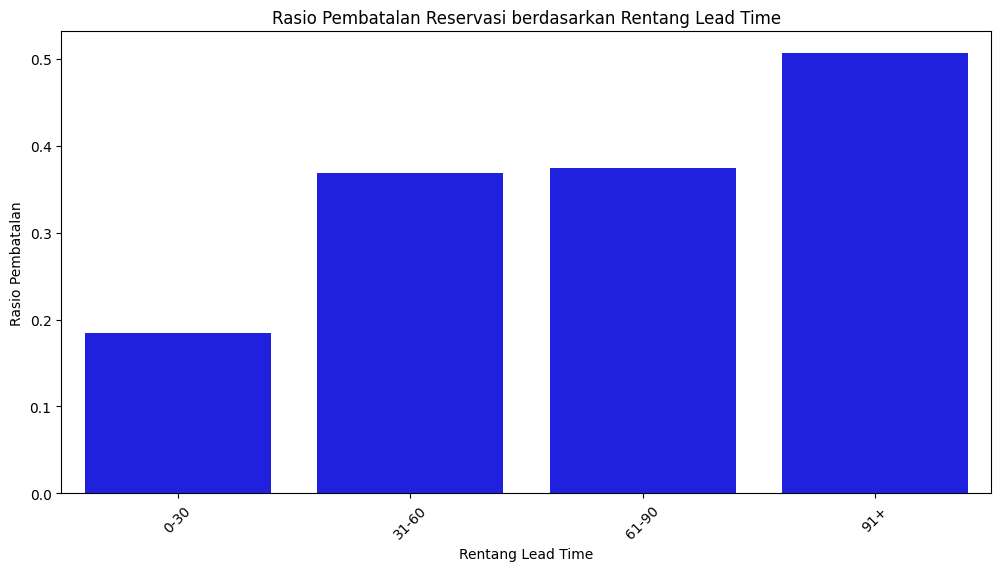

In [ ]:
#1
lead_time_cancelled = df[df['is_canceled'] == 1].groupby('lead_time').size().reset_index(name='cancelled_count')
lead_time_total = df.groupby('lead_time').size().reset_index(name='total_count')
lead_time_summary = pd.merge(lead_time_cancelled, lead_time_total, on='lead_time', how='outer').fillna(0)

#Mengelompokkan lead_time berdasarkan rentang
def categorize_lead_time(lead_time):
    if lead_time <= 30:
        return '0-30'
    elif lead_time <= 60:
        return '31-60'
    elif lead_time <= 90:
        return '61-90'
    else:
        return '91+'

#Menerapkan fungsi pengelompokan
lead_time_summary['lead_time_group'] = lead_time_summary['lead_time'].apply(categorize_lead_time)

#Menghitung total pembatalan dan total reservasi per kelompok
lead_time_grouped = lead_time_summary.groupby('lead_time_group').agg({
    'cancelled_count': 'sum',
    'total_count': 'sum'
}).reset_index()

#Menghitung rasio pembatalan
lead_time_grouped['cancel_ratio'] = lead_time_grouped['cancelled_count'] / lead_time_grouped['total_count']

#Visualisasi
plt.figure(figsize=(12, 6))
sns.barplot(data=lead_time_grouped, x='lead_time_group', y='cancel_ratio', color='blue')
plt.title('Rasio Pembatalan Reservasi berdasarkan Rentang Lead Time')
plt.xlabel('Rentang Lead Time')
plt.ylabel('Rasio Pembatalan')
plt.xticks(rotation=45)
plt.show()

## 2

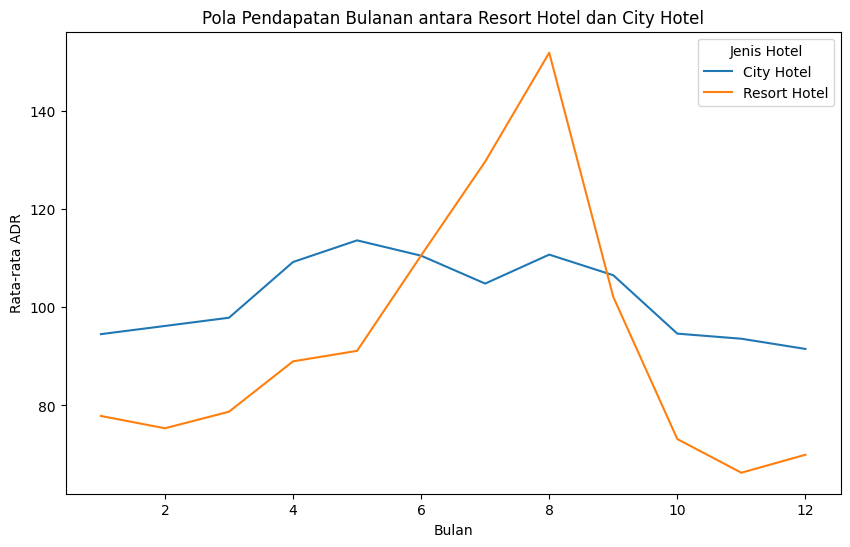

In [ ]:
# Tambahkan kolom bulan
df['month'] = pd.to_datetime(df['reservation_status_date']).dt.month

# Kelompokkan data berdasarkan bulan dan hotel, hitung rata-rata adr
monthly_revenue = df.groupby(['month', 'hotel'])['adr'].mean().unstack()

# Plot
monthly_revenue.plot(kind='line', figsize=(10, 6))
plt.title("Pola Pendapatan Bulanan antara Resort Hotel dan City Hotel")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata ADR")
plt.legend(title="Jenis Hotel")
plt.show()


## 3

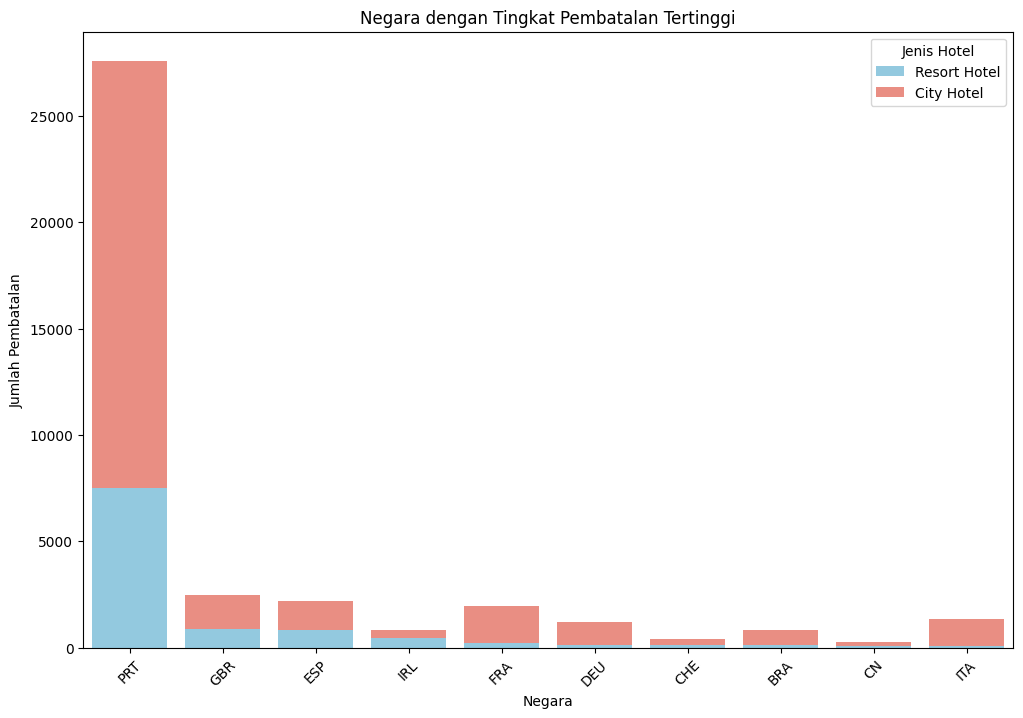

In [ ]:
# 3
# Filter data untuk hanya yang dibatalkan
canceled_data = df[df['is_canceled'] == 1]

# Kelompokkan berdasarkan negara dan jenis hotel, hitung jumlah pembatalan
cancellations_by_country = canceled_data.groupby(['country', 'hotel']).size().unstack(fill_value=0)

# Tampilkan hanya beberapa negara teratas yang paling banyak melakukan pembatalan
top_canceling_countries = cancellations_by_country.nlargest(10, ['Resort Hotel', 'City Hotel']).reset_index()

# Plot menggunakan Seaborn
plt.figure(figsize=(12, 8))
sns.barplot(x='country', y='Resort Hotel', data=top_canceling_countries, color='skyblue', label='Resort Hotel')
sns.barplot(x='country', y='City Hotel', data=top_canceling_countries, color='salmon', label='City Hotel', bottom=top_canceling_countries['Resort Hotel'])
plt.title("Negara dengan Tingkat Pembatalan Tertinggi")
plt.xlabel("Negara")
plt.ylabel("Jumlah Pembatalan")
plt.legend(title="Jenis Hotel")
plt.xticks(rotation=45)
plt.show()


## 4

<ipython-input-13-c1c857860208>:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hotel', y='last_minute_count', data=last_minute_by_hotel, palette='flare')


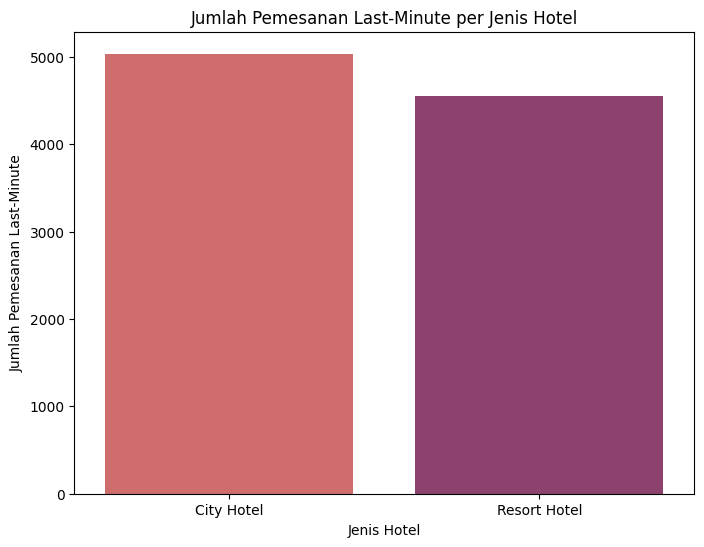

In [ ]:
# 4
# Definisikan pemesanan Last-Minute dengan lead_time <= 3
last_minute_bookings = df[df['lead_time'] <= 3]

# Hitung jumlah pemesanan Last-Minute per jenis hotel
last_minute_by_hotel = last_minute_bookings['hotel'].value_counts().reset_index()
last_minute_by_hotel.columns = ['hotel', 'last_minute_count']

# Plot menggunakan Seaborn
plt.figure(figsize=(8, 6))
sns.barplot(x='hotel', y='last_minute_count', data=last_minute_by_hotel, palette='flare')
plt.title("Jumlah Pemesanan Last-Minute per Jenis Hotel")
plt.xlabel("Jenis Hotel")
plt.ylabel("Jumlah Pemesanan Last-Minute")
plt.show()

# Modul 5

In [ ]:
import pandas as pd
from scipy import stats

data = pd.read_csv('data_cleaned.csv')

# Memisahkan data ADR untuk City Hotel dan Resort Hotel
adr_city = data[data['hotel'] == 'City Hotel']['adr']
adr_resort = data[data['hotel'] == 'Resort Hotel']['adr']

# Menampilkan Hipotesis
print("Hipotesis:")
print("H0: Tidak ada perbedaan signifikan dalam Average Daily Rate (ADR) antara City Hotel dan Resort Hotel.")
print("H1: Terdapat perbedaan signifikan dalam Average Daily Rate (ADR) antara City Hotel dan Resort Hotel.")
print("-" * 50)

# Uji Normalitas menggunakan Kolmogorov-Smirnov Test
ks_city = stats.kstest(adr_city, 'norm')
ks_resort = stats.kstest(adr_resort, 'norm')
print("Uji Normalitas (Kolmogorov-Smirnov Test):")
print(f"P-value untuk City Hotel: {ks_city.pvalue:.8f}")
print(f"P-value untuk Resort Hotel: {ks_resort.pvalue:.8f}")
if ks_city.pvalue < 0.05 or ks_resort.pvalue < 0.05:
    print("Data tidak berdistribusi normal.")
else:
    print("Data berdistribusi normal.")
print("-" * 50)

# Uji Homogenitas Varians menggunakan Levene’s Test
levene_test = stats.levene(adr_city, adr_resort)
print("Uji Homogenitas Varians (Levene's Test):")
print(f"P-value uji Levene: {levene_test.pvalue:.8f}")
equal_var = levene_test.pvalue >= 0.05
if equal_var:
    print("Varians dianggap homogen (p-value >= 0.05)")
else:
    print("Varians dianggap tidak homogen (p-value < 0.05)")
print("-" * 50)

# Melakukan T-test dengan equal_var berdasarkan hasil uji Levene
t_stat, p_value = stats.ttest_ind(adr_city, adr_resort, equal_var=equal_var)
print("Hasil Uji T-test:")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.8e}")
if p_value < 0.05:
    print("Tolak H0: Terdapat perbedaan signifikan antara ADR City Hotel dan Resort Hotel.")
else:
    print("Gagal menolak H0: Tidak terdapat perbedaan signifikan antara ADR City Hotel dan Resort Hotel.")


Hipotesis:
H0: Tidak ada perbedaan signifikan dalam Average Daily Rate (ADR) antara City Hotel dan Resort Hotel.
H1: Terdapat perbedaan signifikan dalam Average Daily Rate (ADR) antara City Hotel dan Resort Hotel.
--------------------------------------------------
Uji Normalitas (Kolmogorov-Smirnov Test):
P-value untuk City Hotel: 0.00000000
P-value untuk Resort Hotel: 0.00000000
Data tidak berdistribusi normal.
--------------------------------------------------
Uji Homogenitas Varians (Levene's Test):
P-value uji Levene: 0.00000000
Varians dianggap tidak homogen (p-value < 0.05)
--------------------------------------------------
Hasil Uji T-test:
T-statistic: 25.5759
P-value: 1.80177266e-143
Tolak H0: Terdapat perbedaan signifikan antara ADR City Hotel dan Resort Hotel.
